# Multi-Terminal 3D Networks: Spherical Terminals Anywhere

Same multi-terminal generalization as `percolation_3d_multi_terminal_faces.ipynb` (several independent terminals, each with its own prescribed voltage, solved via `multi_terminal_solver.solve_multi_terminal`) -- but terminals here are small spherical regions placed **anywhere** in the unit cube, not confined to the `x<0.1`/`x>0.9` faces at all.

Together, the two multi-terminal notebooks cover the two ends of the comparison: `percolation_3d_multi_terminal_faces.ipynb` keeps the `x<0.1`/`x>0.9` slab convention so its results can be checked directly against the 2D case; this notebook drops that convention and places terminals **randomly** anywhere in the cube (Sec. 3), the more realistic setting for a follow-on transport simulation of a plant vascular network, where roots/leaves aren't confined to two opposite faces.

This is the more general (and more work) of the two approaches: since terminals aren't tied to the existing boundary-face convention, the x-threshold-hardwired machinery in `find_path`/`prune_dead_end_nodes`/`build_connected_path` no longer applies. Instead this notebook uses fully generic siblings:
- `path_analysis.connected_components` -- partitions the whole contact graph by the same shared-stick adjacency `find_path` uses, but with no x>0.9 flag and no single designated start node.
- `multi_terminal_solver.assign_nodes_to_spherical_terminals` -- groups contact nodes by Euclidean distance to each terminal's center.
- `pruning.prune_dead_end_nodes_generic` -- same iterative degree-1 removal as `prune_dead_end_nodes`, but protects any node belonging to ANY terminal instead of an x-range.
- `multi_terminal_solver.validate_multi_terminal_percolation` -- a network is usable only if every terminal has a surviving node in the SAME connected component (otherwise it's electrically isolated and its current would be forced to ~0 regardless of its prescribed voltage).

`utils/pipeline_utils_3d.py: run_full_pipeline_3d_spherical_terminals` wires all of this together; see that function's docstring for the exact call order.

---
## 1. Setup and imports

In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    utils_path = "/content/drive/MyDrive/ColabProject/utils"
    print("Environment: Google Colab")
except ImportError:
    utils_path = os.path.abspath(os.path.join(os.getcwd(), "..", "utils"))
    print("Environment: Local")

if utils_path not in sys.path:
    sys.path.append(utils_path)

print(f"Utils path: {utils_path}")


Environment: Local
Utils path: <project_root>/utils


In [2]:
from point_generator_3d import generate_points_3d
from pipeline_utils_3d import run_full_pipeline_3d_spherical_terminals
from multi_terminal_solver import (
    solve_multi_terminal, multi_terminal_pinv_currents,
    assign_nodes_to_spherical_terminals, validate_multi_terminal_percolation,
    assign_terminal_voltages, print_terminal_roles,
)
from path_analysis import connected_components
from network_visualization_3d import plot_network_3d_colored_by_voltage, plot_network_3d_colored_by_resistance

print("Imports OK")


Imports OK


---
## Experiment tracking

In [3]:
from experiment_manager import setup_experiment

exp_manager = setup_experiment()


EXPERIMENT CONFIGURATION
  Environment: Local
  Experiment #: 812
  Timestamp: 20260727_135840
  Results directory: <project_root>/utils/../experiments/exp_812



---
## 2. Validation: hand-built networks with a known answer

Same two validation cases as `percolation_3d_multi_terminal_faces.ipynb` -- they exercise `solve_multi_terminal` directly and don't depend on how terminals were selected, so they're identical here (repeated for a self-contained notebook).

### 2.1 Three-terminal star (closed-form check)

One internal node connected to 3 terminals by edges of different lengths (distance-dependent resistance: `R_i = R0 * L_i`):

`Vc = (V1/R1 + V2/R2 + V3/R3) / (1/R1 + 1/R2 + 1/R3)`

In [4]:
intersections = [(0.5, 0.5, 0.5), (0, 0, 0), (2, 0, 0), (0, 3, 0)]
segment_to_nodes = {0: (0, 1), 1: (0, 2), 2: (0, 3)}
terminal_nodes = [1, 2, 3]
terminal_voltages = [1.0, 0.0, 0.6]
R0 = 1000.0

lengths = [np.linalg.norm(np.array(intersections[0]) - np.array(intersections[t])) for t in terminal_nodes]
expected_Vc = sum(v / L for v, L in zip(terminal_voltages, lengths)) / sum(1 / L for L in lengths)

res_star = solve_multi_terminal(intersections, segment_to_nodes, terminal_nodes, terminal_voltages,
                                k=R0, distance_dependent=True)

print(f"Internal node voltage: computed={res_star['voltages'][0]:.6f}  expected={expected_Vc:.6f}")
print(f"Current imbalance: {res_star['current_imbalance']:.2e} (should be ~0)")
assert abs(res_star['voltages'][0] - expected_Vc) < 1e-9
assert abs(res_star['current_imbalance']) < 1e-9
print("OK: matches the closed-form nodal-analysis formula exactly")


Internal node voltage: computed=0.646703  expected=0.646703
Current imbalance: -8.13e-20 (should be ~0)
OK: matches the closed-form nodal-analysis formula exactly


### 2.2 Four-terminal network with a loop (pseudoinverse cross-check)

Two internal nodes (A, B), 4 terminals, one bridging edge -- a genuine cycle, cross-checked against `multi_terminal_pinv_currents` (independently-coded, no `build_incidence_matrix`).

In [5]:
intersections_g = [(0.3, 0.5, 0.5), (0, 0, 0), (0, 1, 0), (1, 0, 1), (1, 1, 1), (0.7, 0.5, 0.5)]
# node indices: 0=A (internal), 1=T1, 2=T2, 3=T3, 4=T4, 5=B (internal)
segment_to_nodes_g = {0: (1, 0), 1: (2, 0), 2: (0, 5), 3: (5, 3), 4: (5, 4), 5: (1, 5)}
terminal_nodes_g = [1, 2, 3, 4]
terminal_voltages_g = [1.0, 0.3, 0.0, 0.7]

res_grid = solve_multi_terminal(intersections_g, segment_to_nodes_g, terminal_nodes_g, terminal_voltages_g,
                                k=R0, distance_dependent=True)
res_grid_pinv = multi_terminal_pinv_currents(intersections_g, segment_to_nodes_g, terminal_nodes_g, terminal_voltages_g,
                                             k=R0, distance_dependent=True)

print(f"Internal voltages (A, B): solver={res_grid['voltages'][0]:.6f}, {res_grid['voltages'][5]:.6f}")
print(f"                          pinv  ={res_grid_pinv['voltages'][0]:.6f}, {res_grid_pinv['voltages'][5]:.6f}")
print(f"Current imbalance: {res_grid['current_imbalance']:.2e} (should be ~0)")

assert np.allclose(res_grid['voltages'], res_grid_pinv['voltages'], atol=1e-9)
assert abs(res_grid['current_imbalance']) < 1e-9
for t in terminal_nodes_g:
    assert abs(res_grid['terminal_currents'][t] - res_grid_pinv['terminal_currents'][t]) < 1e-9
print("OK: matches the independent pseudoinverse solver exactly")


Internal voltages (A, B): solver=0.606939, 0.562091
                          pinv  =0.606939, 0.562091
Current imbalance: 8.13e-20 (should be ~0)
OK: matches the independent pseudoinverse solver exactly


### 2.3 Degenerate case: an isolated terminal must be rejected before solving

A "terminal" placed far from everything else (radius too small to touch any contact) must be caught by `validate_multi_terminal_percolation` -- confirming the validity check actually catches the case it's meant to catch, rather than silently reaching `solve_multi_terminal` with a meaningless answer.

In [6]:
# Two sticks that touch near the origin (one real contact), plus a terminal
# placed at (0.5, 0.5, 0.5) with a radius far too small to reach that contact.
p1 = [(0, 0, 0), (0.05, -0.05, 0)]
p2 = [(0.1, 0, 0), (0.05, 0.05, 0)]
from intersection_utils_3d import identify_contacts_3d
inter_pts, graph, gaps = identify_contacts_3d(p1, p2, contact_distance=1e-6)
print(f"Contacts found: {len(inter_pts)}  (all near the origin)")

terminal_groups_bad = assign_nodes_to_spherical_terminals(
    inter_pts, terminal_centers=[(0, 0, 0), (0.5, 0.5, 0.5)], terminal_radii=[0.2, 0.05]
)
print(f"Terminal group sizes: {[len(g) for g in terminal_groups_bad]}  (second terminal should be empty)")

components = connected_components(graph)
node_to_component = {n: c for c, comp in enumerate(components) for n in comp}
is_valid = validate_multi_terminal_percolation(terminal_groups_bad, node_to_component)
print(f"validate_multi_terminal_percolation: {is_valid}  (must be False)")
assert not is_valid
print("OK: the isolated/empty terminal is correctly rejected before any solve is attempted")


Contacts found: 1  (all near the origin)
Terminal group sizes: [1, 0]  (second terminal should be empty)
validate_multi_terminal_percolation: False  (must be False)
OK: the isolated/empty terminal is correctly rejected before any solve is attempted


---
## 3. Application to real random 3D networks

Terminal centers and radii are now sampled **randomly** in the unit cube (not hand-picked) -- the setting this notebook is meant to prepare: a plant's roots/leaves aren't confined to two opposite faces or to positions an experimenter chooses in advance, so a follow-on transport simulation needs the source/sink layout itself to be a random input, not a fixed illustration. `sample_random_terminals` below does simple rejection sampling: centers are drawn uniformly, keeping each sphere fully inside the cube and at least `min_gap` away from every previously accepted terminal (so terminals don't overlap by construction). Voltages are drawn independently via `assign_terminal_voltages(mode="random")` rather than the fixed alternating pattern -- source/drain roles then simply fall out of the sign of `solve['terminal_currents']` (negative = current leaves the terminal into the network = source; positive = sink), exactly as in `percolation_2d_multi_terminal.ipynb`.

In [7]:
def sample_random_terminals(n_terminals, radius_range=(0.12, 0.22), min_gap=0.05, seed=None, max_tries=2000):
    """
    Randomly place n_terminals non-overlapping spherical terminals in the
    unit cube by rejection sampling: each candidate (center, radius) is
    accepted only if the sphere stays inside the cube and is at least
    min_gap away from every already-accepted terminal's sphere.
    """
    rng = np.random.RandomState(seed)
    centers, radii = [], []
    for i in range(n_terminals):
        for _ in range(max_tries):
            r = rng.uniform(*radius_range)
            c = rng.uniform(r, 1.0 - r, size=3)
            if all(np.linalg.norm(c - np.array(c2)) >= r + r2 + min_gap for c2, r2 in zip(centers, radii)):
                centers.append(tuple(c))
                radii.append(r)
                break
        else:
            raise RuntimeError(f"could not place terminal {i + 1}/{n_terminals} after {max_tries} tries "
                               f"(try a smaller radius_range/min_gap)")
    return centers, radii

print("sample_random_terminals defined")


sample_random_terminals defined


### 3.1 Three randomly placed terminals

Terminal centers: [(np.float64(0.802), np.float64(0.678), np.float64(0.821)), (np.float64(0.256), np.float64(0.774), np.float64(0.211)), (np.float64(0.53), np.float64(0.217), np.float64(0.419))]
Terminal radii: [0.17, 0.165, 0.155]
Terminal voltages: [np.float64(0.859), np.float64(0.373), np.float64(0.555)]
Percolating multi-terminal network found on attempt 1
Terminal currents: {277: np.float64(-0.0005537828738310163), 278: np.float64(0.00022625424524831783), 279: np.float64(0.0003275286285827037)}
Current imbalance: 5.20e-18 (should be ~0)
Terminal roles:
    node   277   V=+0.859   I=-5.538e-04   ->  SOURCE
    node   278   V=+0.373   I=+2.263e-04   <-  DRAIN
    node   279   V=+0.555   I=+3.275e-04   <-  DRAIN


<project_root>/utils/multi_terminal_solver.py:92: RuntimeWarning: divide by zero encountered in matmul
  L = A.T @ G_matrix @ A
<project_root>/utils/multi_terminal_solver.py:92: RuntimeWarning: overflow encountered in matmul
  L = A.T @ G_matrix @ A
<project_root>/utils/multi_terminal_solver.py:92: RuntimeWarning: invalid value encountered in matmul
  L = A.T @ G_matrix @ A
<project_root>/utils/multi_terminal_solver.py:133: RuntimeWarning: divide by zero encountered in matmul
  voltage_drops = -A @ V_full
<project_root>/utils/multi_terminal_solver.py:133: RuntimeWarning: overflow encountered in matmul
  voltage_drops = -A @ V_full
<project_root>/utils/multi_terminal_solver.py:133: RuntimeWarning: invalid value encountered in matmul
  voltage_drops = -A @ V_full
<project_root>/utils/multi_terminal_solver.py:134: RuntimeWarning: divide by zero encountered in matmul
  I = G_matrix @ voltage_drops
<project_root>/utils/multi_terminal_solver.py:134: RuntimeWarning: overflow encountered in ma

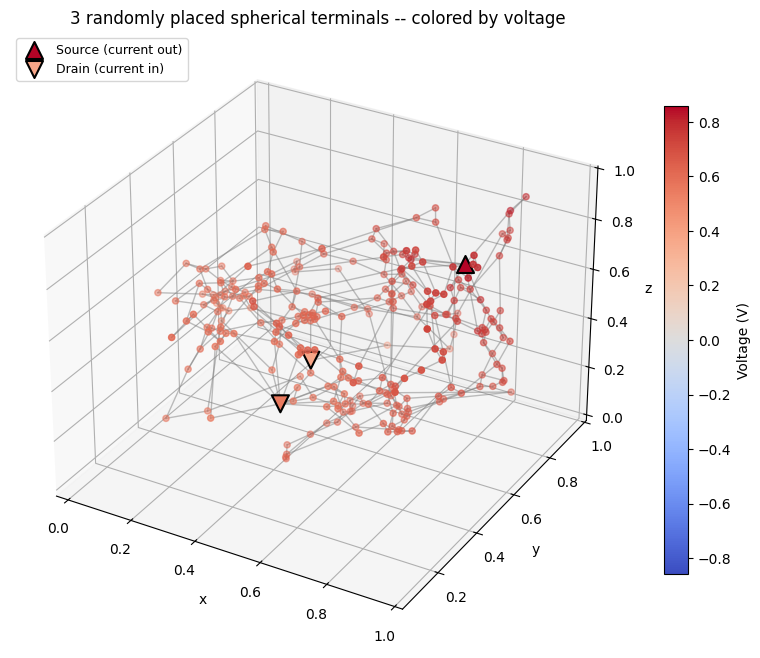

  [OK] Figure saved: spherical_3terminals_voltage.png


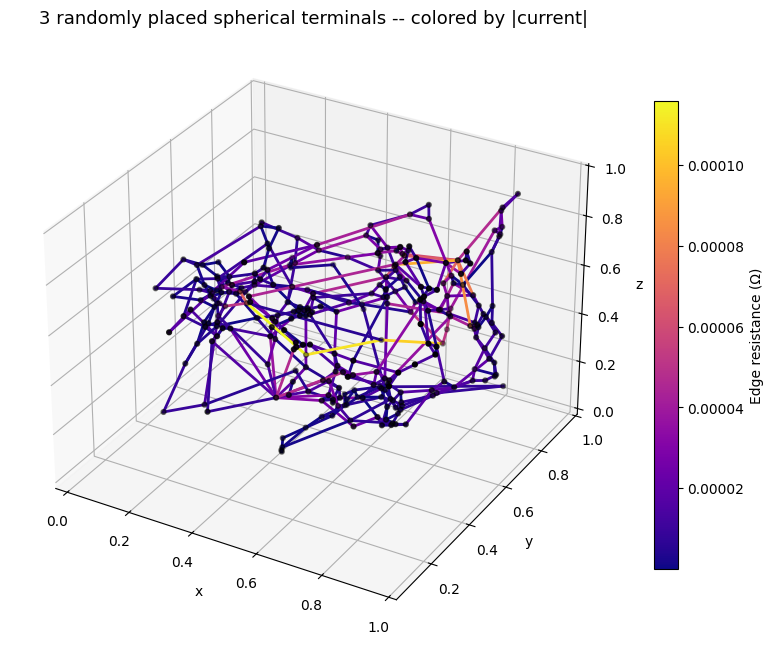

  [OK] Figure saved: spherical_3terminals_current.png


'<project_root>/utils/../experiments/exp_812/spherical_3terminals_current.png'

In [8]:
N3, a3, cd3 = 80, 0.6, 0.08
centers3, radii3 = sample_random_terminals(3, radius_range=(0.15, 0.22), min_gap=0.05, seed=31)
voltages3 = assign_terminal_voltages(3, mode="random", seed=32)

np.random.seed(30)
points_1, points_2, dirs = [], [], []
generate_points_3d(N3, points_1, points_2, dirs, a3, enforce_bounds=True)

res3 = None
for attempt in range(1, 31):
    res3 = run_full_pipeline_3d_spherical_terminals(
        points_1, points_2, N=N3, a=a3, contact_distance=cd3,
        terminal_centers=centers3, terminal_radii=radii3, terminal_voltages=voltages3,
        k=1000.0, verbose=False,
    )
    if res3.get("has_percolation"):
        break
    points_1, points_2, dirs = [], [], []
    generate_points_3d(N3, points_1, points_2, dirs, a3, enforce_bounds=True)

print(f"Terminal centers: {[tuple(round(x, 3) for x in c) for c in centers3]}")
print(f"Terminal radii: {[round(r, 3) for r in radii3]}")
print(f"Terminal voltages: {[round(v, 3) for v in voltages3]}")
print(f"Percolating multi-terminal network found on attempt {attempt}")
print(f"Terminal currents: {res3['solve']['terminal_currents']}")
print(f"Current imbalance: {res3['solve']['current_imbalance']:.2e} (should be ~0)")
assert abs(res3['solve']['current_imbalance']) < 1e-6 * max(abs(v) for v in res3['solve']['terminal_currents'].values())

print_terminal_roles(res3['terminal_node_indices'], res3['terminal_voltages'], res3['solve']['terminal_currents'],
                    title="Terminal roles:")

fig = plot_network_3d_colored_by_voltage(
    res3["merged_intersections"], res3["merged_segment_to_nodes"], res3["solve"]["voltages"],
    terminal_nodes=res3["terminal_node_indices"], terminal_currents=res3["solve"]["terminal_currents"], title="3 randomly placed spherical terminals -- colored by voltage"
)
plt.show()
exp_manager.save_figure(fig, "spherical_3terminals_voltage.png")

fig2 = plot_network_3d_colored_by_resistance(
    res3["merged_intersections"], res3["merged_segment_to_nodes"], np.abs(res3["solve"]["currents"]),
    title="3 randomly placed spherical terminals -- colored by |current|", cmap_name="plasma"
)
plt.show()
exp_manager.save_figure(fig2, "spherical_3terminals_current.png")


### 3.2 Five randomly placed terminals

<project_root>/utils/multi_terminal_solver.py:108: RuntimeWarning: divide by zero encountered in matmul
  b = -L_ib @ V_boundary
<project_root>/utils/multi_terminal_solver.py:108: RuntimeWarning: overflow encountered in matmul
  b = -L_ib @ V_boundary
<project_root>/utils/multi_terminal_solver.py:108: RuntimeWarning: invalid value encountered in matmul
  b = -L_ib @ V_boundary


Terminal centers: [(np.float64(0.155), np.float64(0.634), np.float64(0.153)), (np.float64(0.581), np.float64(0.259), np.float64(0.632)), (np.float64(0.447), np.float64(0.39), np.float64(0.358)), (np.float64(0.689), np.float64(0.173), np.float64(0.207)), (np.float64(0.607), np.float64(0.874), np.float64(0.336))]
Terminal radii: [0.12, 0.109, 0.173, 0.108, 0.126]
Terminal voltages: [np.float64(0.375), np.float64(0.951), np.float64(0.732), np.float64(0.599), np.float64(0.156)]
Percolating multi-terminal network found on attempt 7
Terminal currents: {577: np.float64(0.0005297384506232941), 578: np.float64(-0.0015265899975975585), 579: np.float64(-0.0002014053500383652), 580: np.float64(0.000376918290054195), 581: np.float64(0.000821338606958375)}
Current imbalance: -5.97e-17 (should be ~0)
Terminal roles:
    node   577   V=+0.375   I=+5.297e-04   <-  DRAIN
    node   578   V=+0.951   I=-1.527e-03   ->  SOURCE
    node   579   V=+0.732   I=-2.014e-04   ->  SOURCE
    node   580   V=+0.599 

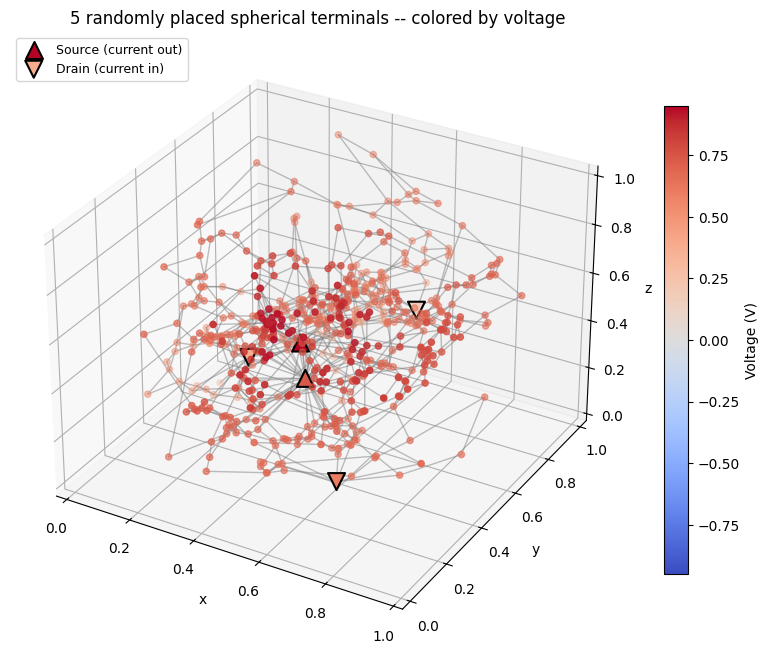

  [OK] Figure saved: spherical_5terminals_voltage.png


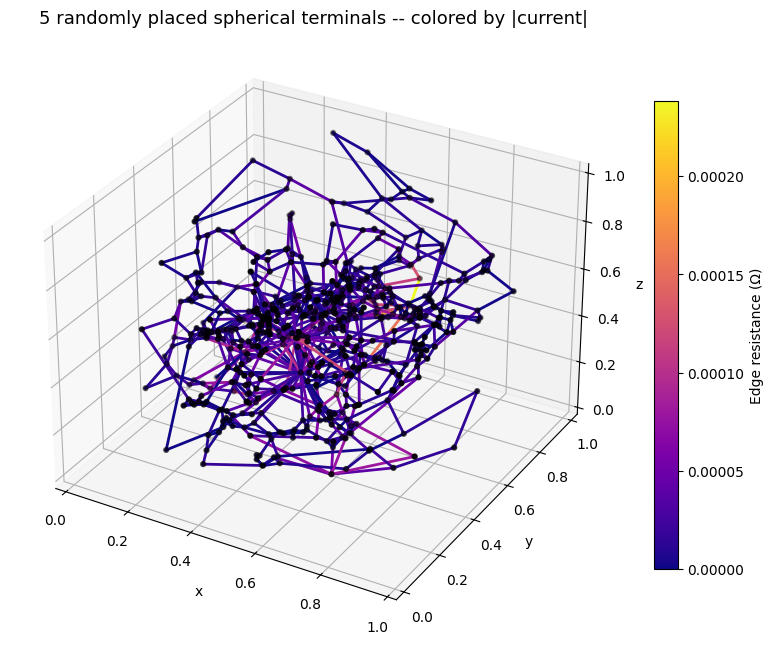

  [OK] Figure saved: spherical_5terminals_current.png


'<project_root>/utils/../experiments/exp_812/spherical_5terminals_current.png'

In [9]:
N5, a5, cd5 = 120, 0.6, 0.08
centers5, radii5 = sample_random_terminals(5, radius_range=(0.1, 0.18), min_gap=0.04, seed=41)
voltages5 = assign_terminal_voltages(5, mode="random", seed=42)

np.random.seed(40)
points_1, points_2, dirs = [], [], []
generate_points_3d(N5, points_1, points_2, dirs, a5, enforce_bounds=True)

res5 = None
for attempt in range(1, 31):
    res5 = run_full_pipeline_3d_spherical_terminals(
        points_1, points_2, N=N5, a=a5, contact_distance=cd5,
        terminal_centers=centers5, terminal_radii=radii5, terminal_voltages=voltages5,
        k=1000.0, verbose=False,
    )
    if res5.get("has_percolation"):
        break
    points_1, points_2, dirs = [], [], []
    generate_points_3d(N5, points_1, points_2, dirs, a5, enforce_bounds=True)

print(f"Terminal centers: {[tuple(round(x, 3) for x in c) for c in centers5]}")
print(f"Terminal radii: {[round(r, 3) for r in radii5]}")
print(f"Terminal voltages: {[round(v, 3) for v in voltages5]}")
print(f"Percolating multi-terminal network found on attempt {attempt}")
print(f"Terminal currents: {res5['solve']['terminal_currents']}")
print(f"Current imbalance: {res5['solve']['current_imbalance']:.2e} (should be ~0)")
assert abs(res5['solve']['current_imbalance']) < 1e-6 * max(abs(v) for v in res5['solve']['terminal_currents'].values())

print_terminal_roles(res5['terminal_node_indices'], res5['terminal_voltages'], res5['solve']['terminal_currents'],
                    title="Terminal roles:")

fig = plot_network_3d_colored_by_voltage(
    res5["merged_intersections"], res5["merged_segment_to_nodes"], res5["solve"]["voltages"],
    terminal_nodes=res5["terminal_node_indices"], terminal_currents=res5["solve"]["terminal_currents"], title="5 randomly placed spherical terminals -- colored by voltage"
)
plt.show()
exp_manager.save_figure(fig, "spherical_5terminals_voltage.png")

fig2 = plot_network_3d_colored_by_resistance(
    res5["merged_intersections"], res5["merged_segment_to_nodes"], np.abs(res5["solve"]["currents"]),
    title="5 randomly placed spherical terminals -- colored by |current|", cmap_name="plasma"
)
plt.show()
exp_manager.save_figure(fig2, "spherical_5terminals_current.png")


### 3.3 Seven terminals, denser/shorter-stick network, tighter packing

Different from 3.1/3.2 on two axes at once: more terminals (7, smaller and packed closer together via a tighter `min_gap`) AND a denser network of shorter sticks (higher `N`, smaller `a`, tighter `contact_distance`) -- stresses both `sample_random_terminals`' rejection sampling (more spheres to fit) and the generic connectivity path (`connected_components` / `prune_dead_end_nodes_generic`) on a bigger, denser contact graph.

Terminal centers: [(np.float64(0.148), np.float64(0.379), np.float64(0.611)), (np.float64(0.865), np.float64(0.222), np.float64(0.409)), (np.float64(0.49), np.float64(0.246), np.float64(0.28)), (np.float64(0.306), np.float64(0.43), np.float64(0.149)), (np.float64(0.675), np.float64(0.55), np.float64(0.664)), (np.float64(0.345), np.float64(0.583), np.float64(0.397)), (np.float64(0.464), np.float64(0.223), np.float64(0.787))]
Terminal radii: [0.114, 0.094, 0.109, 0.112, 0.118, 0.097, 0.081]
Terminal voltages: [np.float64(0.823), np.float64(0.026), np.float64(0.211), np.float64(0.618), np.float64(0.098), np.float64(0.62), np.float64(0.054)]
Percolating multi-terminal network found on attempt 1
Terminal currents: {460: np.float64(-0.0012507969958472026), 461: np.float64(0.00024159450405099385), 462: np.float64(0.0007096152116427687), 463: np.float64(-0.0008150486291015708), 464: np.float64(0.0005389776992308739), 465: np.float64(-0.000224229369834843), 466: np.float64(0.0007998875798589699

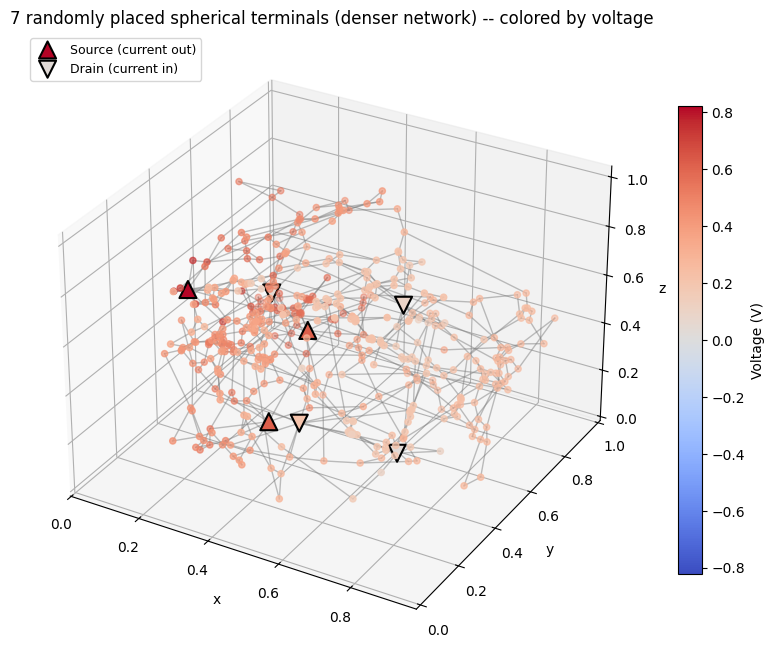

  [OK] Figure saved: spherical_7terminals_voltage.png


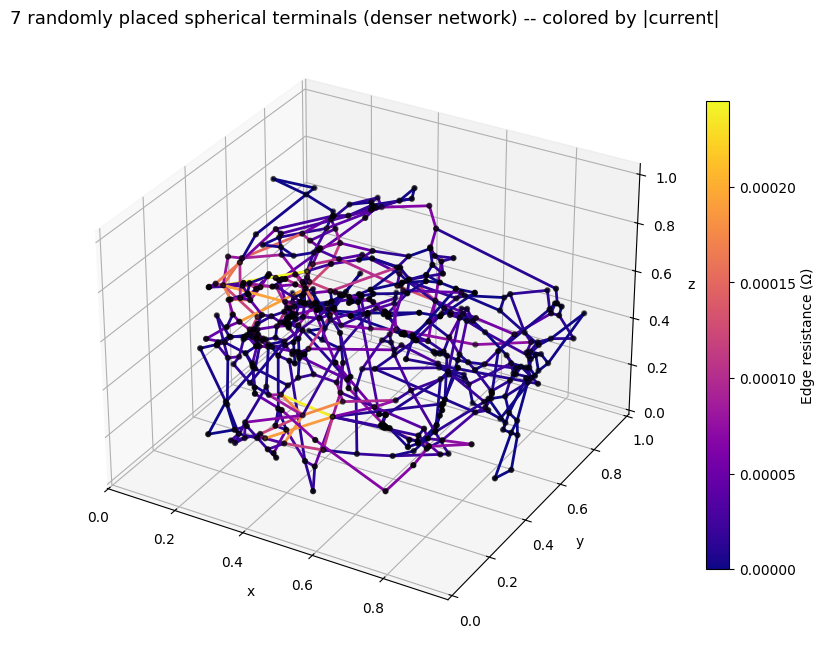

  [OK] Figure saved: spherical_7terminals_current.png


'<project_root>/utils/../experiments/exp_812/spherical_7terminals_current.png'

In [10]:
N7, a7, cd7 = 200, 0.4, 0.05
centers7, radii7 = sample_random_terminals(7, radius_range=(0.08, 0.13), min_gap=0.03, seed=51)
voltages7 = assign_terminal_voltages(7, mode="random", seed=52)

np.random.seed(51)
points_1, points_2, dirs = [], [], []
generate_points_3d(N7, points_1, points_2, dirs, a7, enforce_bounds=True)

res7 = None
for attempt in range(1, 31):
    res7 = run_full_pipeline_3d_spherical_terminals(
        points_1, points_2, N=N7, a=a7, contact_distance=cd7,
        terminal_centers=centers7, terminal_radii=radii7, terminal_voltages=voltages7,
        k=1000.0, verbose=False,
    )
    if res7.get("has_percolation"):
        break
    points_1, points_2, dirs = [], [], []
    generate_points_3d(N7, points_1, points_2, dirs, a7, enforce_bounds=True)

print(f"Terminal centers: {[tuple(round(x, 3) for x in c) for c in centers7]}")
print(f"Terminal radii: {[round(r, 3) for r in radii7]}")
print(f"Terminal voltages: {[round(v, 3) for v in voltages7]}")
print(f"Percolating multi-terminal network found on attempt {attempt}")
print(f"Terminal currents: {res7['solve']['terminal_currents']}")
print(f"Current imbalance: {res7['solve']['current_imbalance']:.2e} (should be ~0)")
assert abs(res7['solve']['current_imbalance']) < 1e-6 * max(abs(v) for v in res7['solve']['terminal_currents'].values())

print_terminal_roles(res7['terminal_node_indices'], res7['terminal_voltages'], res7['solve']['terminal_currents'],
                    title="Terminal roles:")

fig = plot_network_3d_colored_by_voltage(
    res7["merged_intersections"], res7["merged_segment_to_nodes"], res7["solve"]["voltages"],
    terminal_nodes=res7["terminal_node_indices"], terminal_currents=res7["solve"]["terminal_currents"], title="7 randomly placed spherical terminals (denser network) -- colored by voltage"
)
plt.show()
exp_manager.save_figure(fig, "spherical_7terminals_voltage.png")

fig2 = plot_network_3d_colored_by_resistance(
    res7["merged_intersections"], res7["merged_segment_to_nodes"], np.abs(res7["solve"]["currents"]),
    title="7 randomly placed spherical terminals (denser network) -- colored by |current|", cmap_name="plasma"
)
plt.show()
exp_manager.save_figure(fig2, "spherical_7terminals_current.png")


---
## Notes

- Terminal placement here is fully free (any center/radius anywhere in the cube) -- the tradeoff is a more general (and slightly slower, `O(n^2)` `connected_components`) pipeline compared to `percolation_3d_multi_terminal_faces.ipynb`, which reuses the existing x-threshold machinery unchanged.
- `validate_multi_terminal_percolation` is checked TWICE inside `run_full_pipeline_3d_spherical_terminals` -- once right after `connected_components` (cheap pre-filter) and again after dead-end pruning (pruning can still isolate a terminal that had contacts before pruning). Section 2.3 confirms the check itself actually rejects a deliberately-isolated terminal.
- As in the faces notebook, `current_imbalance ≈ 0` is checked everywhere -- it's a hard conservation law (Kirchhoff's current law on the whole network), independent of terminal count, placement, or topology.
- Terminal centers/radii are now sampled randomly (`sample_random_terminals`, rejection sampling subject to a minimum pairwise separation) rather than hand-picked, and voltages are drawn randomly too (`assign_terminal_voltages(mode="random")`) -- this is the setup a follow-on plant-transport simulation (random roots/leaves, not two fixed faces) would build on. A retry loop (up to 30 attempts) regenerates the stick network, not the terminal layout, if a given draw doesn't percolate.
- Compare against `percolation_3d_multi_terminal_faces.ipynb`, which keeps the `x<0.1`/`x>0.9` slab convention specifically so its results are comparable to the 2D case.

---
## 4. Save consolidated summary

In [11]:
summary = {
    "experiment": exp_manager.get_info(),
    "validation": {
        "star_Vc": res_star["voltages"][0],
        "star_Vc_expected": expected_Vc,
        "grid_current_imbalance": res_grid["current_imbalance"],
        "isolated_terminal_correctly_rejected": not is_valid,
    },
    "three_terminal_network": {
        "N": N3, "a": a3, "contact_distance": cd3,
        "terminal_centers": centers3, "terminal_radii": radii3,
        "terminal_voltages": res3["terminal_voltages"],
        "terminal_currents": {str(k): v for k, v in res3["solve"]["terminal_currents"].items()},
        "current_imbalance": res3["solve"]["current_imbalance"],
    },
    "five_terminal_network": {
        "N": N5, "a": a5, "contact_distance": cd5,
        "terminal_centers": centers5, "terminal_radii": radii5,
        "terminal_voltages": res5["terminal_voltages"],
        "terminal_currents": {str(k): v for k, v in res5["solve"]["terminal_currents"].items()},
        "current_imbalance": res5["solve"]["current_imbalance"],
    },
    "seven_terminal_denser_network": {
        "N": N7, "a": a7, "contact_distance": cd7,
        "terminal_centers": centers7, "terminal_radii": radii7,
        "terminal_voltages": res7["terminal_voltages"],
        "terminal_currents": {str(k): v for k, v in res7["solve"]["terminal_currents"].items()},
        "current_imbalance": res7["solve"]["current_imbalance"],
    },
}

exp_manager.save_json(summary, "multi_terminal_spherical_summary.json")

print(f"\nAll results saved to: {exp_manager.experiment_dir}")
for f in sorted(os.listdir(exp_manager.experiment_dir)):
    print(f"  - {f}")


  [OK] JSON saved: multi_terminal_spherical_summary.json

All results saved to: <project_root>/utils/../experiments/exp_812
  - multi_terminal_spherical_summary.json
  - spherical_3terminals_current.png
  - spherical_3terminals_voltage.png
  - spherical_5terminals_current.png
  - spherical_5terminals_voltage.png
  - spherical_7terminals_current.png
  - spherical_7terminals_voltage.png
